# Practical Assignment 5: Ensemble Learning and Performance Evaluation

**Course:** Artificial Intelligence and Machine Learning (AIML)  
**Practical:** 5  
**Application:** Dry Bean Variety Classification  
**Dataset:** Dry Bean Dataset – UCI Machine Learning Repository  
**Student Name:** Samarth Kadam  
**Roll Number:** 33  
**PRN:** 202401040131            
**Div:** A

> This practical uses measurements of dry bean seeds to classify each sample into one of seven bean varieties. The notebook implements Stacking, AdaBoost and majority Voting, then compares them with individual classifiers.

## 1. Aim

To implement and evaluate **Stacking, AdaBoost, and Voting ensemble learning techniques** for the multiclass classification of dry bean varieties, and compare their performance with individual machine-learning classifiers using suitable evaluation metrics.

## 2. Problem Statement

The Dry Bean Dataset contains numerical measurements extracted from images of dry bean samples. Each sample belongs to one of seven varieties: **BARBUNYA, BOMBAY, CALI, DERMASON, HOROZ, SEKER, or SIRA**.

The task is to predict the bean variety from its measured shape and size characteristics. This practical compares three ensemble methods—**Stacking, AdaBoost, and majority Voting**—with individual classifiers using the same held-out test data.


## 3. Objectives

1. Load and understand the Dry Bean Dataset.
2. Prepare the data and create a stratified training and testing split.
3. Train and evaluate individual classification models.
4. Implement Stacking with a Logistic Regression meta-classifier.
5. Implement AdaBoost and hard Voting ensembles.
6. Compare all models using classification metrics and interpret the results.


## 4. Theory and Mathematical Background

### 4.1 Ensemble Learning

Ensemble learning combines predictions from multiple models to produce a final prediction. It can improve generalisation when the models make different types of errors.

### 4.2 Stacking

Stacking uses base classifiers and a second-level model called a **meta-classifier**. The meta-classifier learns how to combine the base-model outputs:

\[
\hat y = g(h_1(x),h_2(x),\ldots,h_m(x))
\]

Here, Logistic Regression is the meta-classifier. Cross-validation generates out-of-fold predictions to train it.

### 4.3 AdaBoost

AdaBoost trains weak learners sequentially. After each learner, more weight is given to training samples that were misclassified, so later learners focus on difficult examples. The final prediction combines the learners using learned weights.

For the binary case, the learner weight is:

\[
\alpha_t = \frac{1}{2}\ln\left(\frac{1-\epsilon_t}{\epsilon_t}\right)
\]

where \(\epsilon_t\) is the weighted error of learner \(t\). The implementation uses a decision stump as the weak learner.

### 4.4 Majority Voting

Hard voting predicts the class receiving the most votes from the selected classifiers:

\[
\hat y = \operatorname{mode}\{h_1(x),h_2(x),\ldots,h_m(x)\}
\]

### 4.5 Classification Metrics

- **Accuracy:** proportion of all predictions that are correct.
- **Precision:** proportion of predicted positives that are correct.
- **Recall:** proportion of actual positives that are correctly identified.
- **F1-score:** harmonic mean of precision and recall.

Macro precision, recall, and F1-score are calculated for each class and then averaged equally across the seven varieties. A confusion matrix shows actual classes against predicted classes.

\[
Precision=\frac{TP}{TP+FP},\quad Recall=\frac{TP}{TP+FN}
\]

\[
F1=2\cdot\frac{Precision\cdot Recall}{Precision+Recall}
\]


## 5. Algorithms

### 5.1 Stacking Algorithm
1. Select diverse base classifiers.
2. Divide the training data into folds.
3. Generate out-of-fold predictions from each base classifier.
4. Use these predictions as inputs to train a meta-classifier.
5. Refit the base classifiers on the complete training set.
6. For a new sample, combine base predictions using the trained meta-classifier.

### 5.2 AdaBoost Algorithm
1. Assign equal initial weights to all training samples.
2. Train a weak learner using the weighted training data.
3. Calculate its weighted classification error.
4. Increase the importance of incorrectly classified samples.
5. Repeat for the chosen number of estimators.
6. Combine weak learners according to their learned weights.

### 5.3 Voting Algorithm
1. Train the selected base classifiers.
2. Obtain one predicted class from each classifier.
3. Count the votes for each class.
4. Select the class with the largest number of votes.

## 6. Required Libraries

- **NumPy and Pandas:** numerical and tabular data processing.
- **Matplotlib and Seaborn:** visualisations.
- **Scikit-learn:** preprocessing, classifiers, ensemble methods, and evaluation.
- **ucimlrepo:** downloads the Dry Bean Dataset from UCI.

An internet connection is required for the initial dataset download.


In [1]:
# Install the UCI dataset access package if it is not already installed.
%pip -q install ucimlrepo

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import sklearn
from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import (
    RandomForestClassifier, StackingClassifier,
    AdaBoostClassifier, VotingClassifier
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix
)

RANDOM_STATE = 42
print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.6.1


## 7. Dataset Description and Preprocessing

### 7.1 Dataset Description

The **Dry Bean Dataset** is available from the UCI Machine Learning Repository. It contains **13,611 instances**, **16 numerical features**, and **7 target classes**.

The seven varieties are:
- BARBUNYA
- BOMBAY
- CALI
- DERMASON
- HOROZ
- SEKER
- SIRA

The features describe seed geometry and shape, including area, perimeter, major and minor axis lengths, aspect ratio, eccentricity, convex area, equivalent diameter, extent, solidity, roundness, compactness, and shape-factor measurements.

### 7.2 Preprocessing

1. Inspect dataset dimensions, column names, target classes, and missing values.
2. Separate numerical input features \(X\) from the target label \(y\).
3. Use a stratified 80:20 train-test split to preserve class proportions.
4. Standardise features for scale-sensitive models such as Logistic Regression, KNN, and SVM.
5. Keep imputation and scaling inside pipelines. This ensures they are fitted only on training data during model fitting and cross-validation, reducing data leakage.
6. Tree-based models do not require standardisation.

In [3]:
# Fetch dataset ID 602 from the UCI Machine Learning Repository.
dry_beans = fetch_ucirepo(id=602)

X = dry_beans.data.features.copy()
y = dry_beans.data.targets.copy()

# The UCI target is normally a one-column DataFrame. Convert it to a Series.
if isinstance(y, pd.DataFrame):
    if y.shape[1] != 1:
        raise ValueError("Expected one target column in the Dry Bean dataset.")
    y = y.iloc[:, 0]

# Ensure feature columns are numeric.
X = X.apply(pd.to_numeric, errors="coerce")

print("Dataset shape:", X.shape)
print("Number of target classes:", y.nunique())
print("\nFeature names:")
print(list(X.columns))
print("\nClass distribution:")
display(y.value_counts().rename_axis("Bean variety").to_frame("Count"))
print("\nMissing values in features:", int(X.isna().sum().sum()))
print("Missing target values:", int(y.isna().sum()))
display(X.head())

Dataset shape: (13611, 16)
Number of target classes: 7

Feature names:
['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRatio', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'Roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4']

Class distribution:


,Count
Bean variety,
DERMASON,3546
SIRA,2636
SEKER,2027
HOROZ,1928
CALI,1630
BARBUNYA,1322
BOMBAY,522



Missing values in features: 0
Missing target values: 0


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166


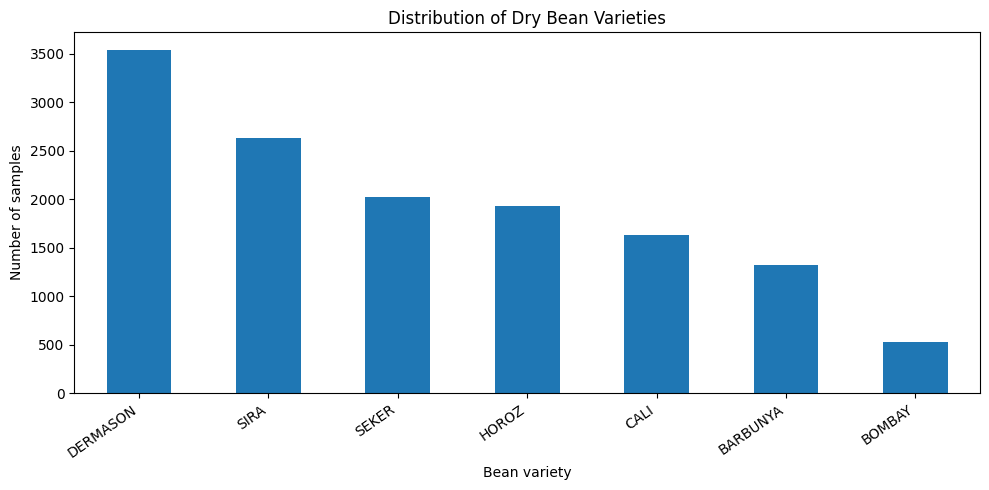

In [4]:
# Visualise the number of samples in each bean variety.
plt.figure(figsize=(10, 5))
y.value_counts().plot(kind="bar")
plt.title("Distribution of Dry Bean Varieties")
plt.xlabel("Bean variety")
plt.ylabel("Number of samples")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()


In [5]:
# Stratified split: 80% training data and 20% testing data.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)
print("\nTraining class proportions:")
display(y_train.value_counts(normalize=True).sort_index().round(3))
print("\nTesting class proportions:")
display(y_test.value_counts(normalize=True).sort_index().round(3))

Training set: (10888, 16)
Testing set: (2723, 16)

Training class proportions:


,proportion
Class,
BARBUNYA,0.097
BOMBAY,0.038
CALI,0.120
DERMASON,0.261
HOROZ,0.142
SEKER,0.149
SIRA,0.194



Testing class proportions:


,proportion
Class,
BARBUNYA,0.097
BOMBAY,0.038
CALI,0.120
DERMASON,0.260
HOROZ,0.142
SEKER,0.149
SIRA,0.194


## 8. Implementation and Outputs

### 8.1 Base Classifiers

Four diverse classifiers are used:

| Classifier | Main idea | Reason for inclusion |
|---|---|---|
| Logistic Regression | Learns linear class boundaries | Simple baseline |
| K-Nearest Neighbours | Predicts from nearby samples | Distance-based approach |
| Support Vector Machine | Learns maximum-margin boundaries | Can model nonlinear patterns with an RBF kernel |
| Random Forest | Combines decision trees | Nonlinear, tree-based approach |

Feature scaling is included in pipelines for Logistic Regression, KNN, and SVM. Random Forest does not require scaling. Median imputation is included in the pipelines as a safeguard for any missing feature values.

In [6]:
base_models = {
    "Logistic Regression": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        LogisticRegression(max_iter=3000, random_state=RANDOM_STATE)
    ),
    "KNN": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=7)
    ),
    "SVM (RBF)": make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
        SVC(kernel="rbf", C=2.0, probability=True, random_state=RANDOM_STATE)
    ),
    "Random Forest": make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestClassifier(
            n_estimators=250,
            random_state=RANDOM_STATE,
            n_jobs=-1
        )
    )
}

for name, model in base_models.items():
    model.fit(X_train, y_train)
    print(name, "trained.")

Logistic Regression trained.
KNN trained.
SVM (RBF) trained.
Random Forest trained.


### 8.2 Stacking Ensemble

The four base classifiers are combined using Logistic Regression as the meta-classifier. Five-fold stratified cross-validation is used internally to generate out-of-fold predictions for training the meta-classifier.

In [7]:
stack_estimators = [(name, model) for name, model in base_models.items()]

stacking_model = StackingClassifier(
    estimators=stack_estimators,
    final_estimator=LogisticRegression(max_iter=3000, random_state=RANDOM_STATE),
    cv=StratifiedKFold(
        n_splits=5, shuffle=True, random_state=RANDOM_STATE
    ),
    stack_method="predict_proba",
    passthrough=False,
    n_jobs=-1
)

stacking_model.fit(X_train, y_train)
print("Stacking ensemble trained successfully.")

Stacking ensemble trained successfully.


### 8.3 AdaBoost Ensemble

AdaBoost uses a decision stump (a decision tree with maximum depth 1) as its weak learner. The ensemble trains 100 sequential learners. The learning rate controls the contribution of each learner.

In [8]:
weak_learner = DecisionTreeClassifier(
    max_depth=1, random_state=RANDOM_STATE
)

# Use the current 'estimator' argument, with a fallback for older scikit-learn versions.
try:
    adaboost_model = AdaBoostClassifier(
        estimator=weak_learner,
        n_estimators=100,
        learning_rate=0.5,
        random_state=RANDOM_STATE
    )
except TypeError:
    adaboost_model = AdaBoostClassifier(
        base_estimator=weak_learner,
        n_estimators=100,
        learning_rate=0.5,
        random_state=RANDOM_STATE
    )

adaboost_model.fit(X_train, y_train)
print("AdaBoost ensemble trained successfully.")

AdaBoost ensemble trained successfully.


### 8.4 Voting Ensemble (Majority Voting)

Hard voting is used. Each base classifier contributes one class prediction, and the class receiving the largest number of votes becomes the final prediction.

In [9]:
voting_model = VotingClassifier(
    estimators=[(name, model) for name, model in base_models.items()],
    voting="hard",
    n_jobs=-1
)

voting_model.fit(X_train, y_train)
print("Hard-voting ensemble trained successfully.")

Hard-voting ensemble trained successfully.


### 8.5 Generate Predictions

All models are evaluated using the same held-out test set. The test set is not used for fitting models or preprocessing steps.

In [10]:
all_models = {
    **base_models,
    "Stacking": stacking_model,
    "AdaBoost": adaboost_model,
    "Voting (Hard)": voting_model
}

predictions = {}
for name, model in all_models.items():
    predictions[name] = model.predict(X_test)

print("Predictions generated for", len(predictions), "models.")

Predictions generated for 7 models.


## 9. Performance Evaluation and Comparison

### 9.1 Classification Metrics

The following metrics are calculated:
- **Accuracy:** overall proportion of correct predictions.
- **Macro Precision:** average precision across the seven bean varieties, giving each class equal weight.
- **Macro Recall:** average recall across the seven bean varieties.
- **Macro F1-score:** harmonic mean of precision and recall, averaged equally across classes.

Macro metrics are included because they show performance across all varieties rather than allowing larger classes to dominate the average.

In [11]:
metric_rows = []
for name, y_pred in predictions.items():
    metric_rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (Macro)": precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Recall (Macro)": recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "F1-score (Macro)": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        )
    })

results = pd.DataFrame(metric_rows).set_index("Model")
results = results.sort_values("F1-score (Macro)", ascending=False)
display(results.round(4))

,Accuracy,Precision (Macro),Recall (Macro),F1-score (Macro)
Model,,,,
SVM (RBF),0.9254,0.9385,0.9366,0.9375
Voting (Hard),0.9236,0.9373,0.9342,0.9357
Stacking,0.9232,0.9372,0.9335,0.9352
Random Forest,0.9221,0.9362,0.9326,0.9343
Logistic Regression,0.9207,0.9349,0.9314,0.9329
KNN,0.9137,0.9290,0.9245,0.9265
AdaBoost,0.8535,0.8684,0.7932,0.8091


### 9.2 Performance Comparison Chart

The chart compares the base classifiers and ensemble models using the same test-set metrics.

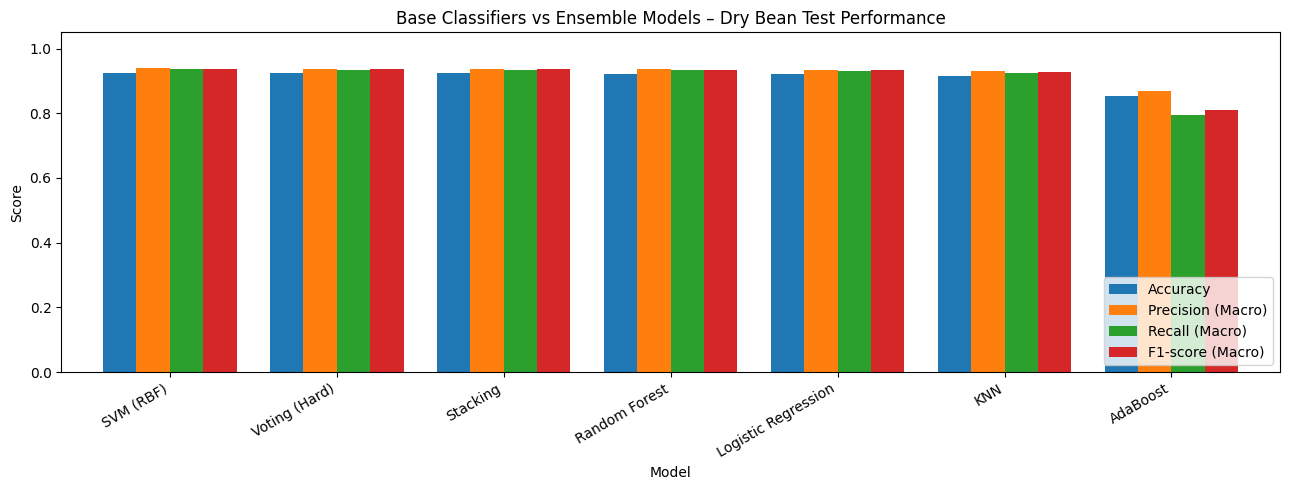

In [12]:
ax = results[
    ["Accuracy", "Precision (Macro)", "Recall (Macro)", "F1-score (Macro)"]
].plot(kind="bar", figsize=(13, 5), ylim=(0, 1.05), width=0.8)

ax.set_title("Base Classifiers vs Ensemble Models – Dry Bean Test Performance")
ax.set_ylabel("Score")
ax.set_xlabel("Model")
plt.xticks(rotation=30, ha="right")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

### 9.3 Confusion Matrices

A confusion matrix shows how many samples of each actual bean variety were assigned to each predicted variety. Rows represent actual classes and columns represent predicted classes.

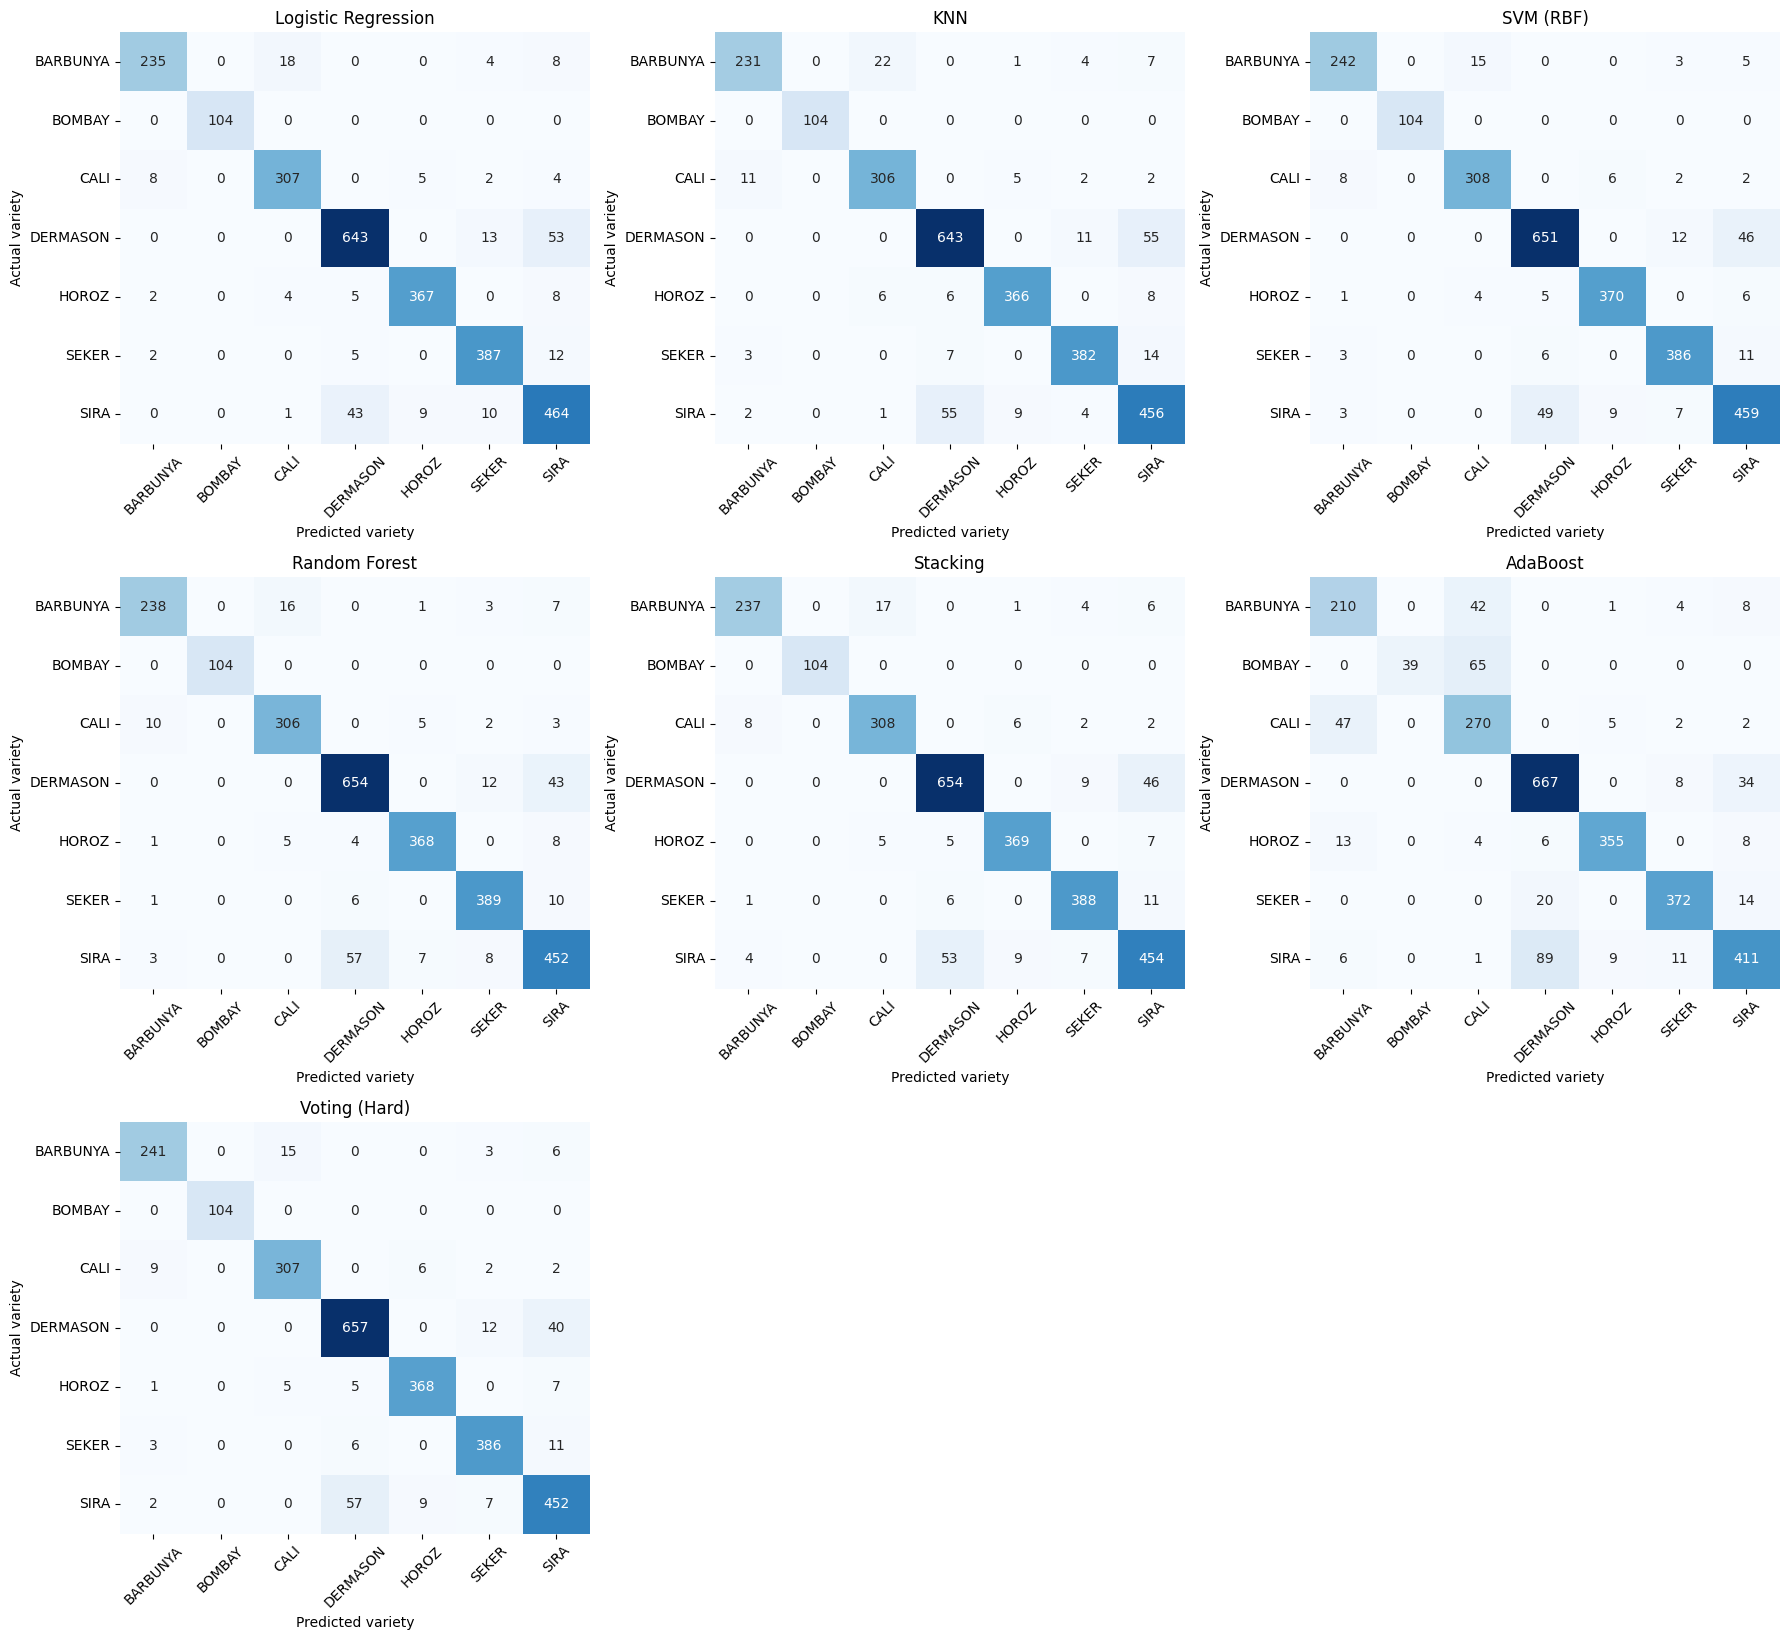

In [13]:
class_labels = list(pd.Series(y).dropna().unique())
class_labels = sorted(class_labels)

n_models = len(predictions)
n_cols = 3
n_rows = int(np.ceil(n_models / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 5.5 * n_rows))
axes = np.array(axes).reshape(-1)

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=class_labels)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
        xticklabels=class_labels, yticklabels=class_labels
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted variety")
    ax.set_ylabel("Actual variety")
    ax.tick_params(axis="x", rotation=45)
    ax.tick_params(axis="y", rotation=0)

for ax in axes[n_models:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

## 10. Conclusion and Critical Analysis

### Findings

- The model with the highest test macro F1-score was **SVM (RBF)**, with a macro F1-score of **0.9375**.
- The best individual classifier was **SVM (RBF)**, with a macro F1-score of **0.9375**.
- Compared with the best individual classifier, the strongest ensemble **Voting (Hard), did not improve** the macro F1-score, Its macro F1-score was 0.9357, slightly lower than SVM (RBF).

Do not assume that an ensemble must outperform every individual classifier. The best choice depends on the measured performance and practical requirements.

### When to Use Each Method

- **Stacking:** when several reasonably strong and diverse models are available and a meta-classifier can learn how to combine them. It is more computationally expensive.
- **AdaBoost:** when sequential weak learners can improve by focusing on difficult training samples. It can be sensitive to noisy labels and outliers.
- **Majority Voting:** when multiple models perform reasonably well and a simple combination is desired.
- **A single classifier:** when it already performs well and is faster, simpler, or easier to interpret.

### Limitations

1. Results depend on the train-test split, model settings, and data quality.
2. The dataset may not represent every bean variety or growing condition.
3. A held-out test set provides an estimate of performance, but validation on independent data would be useful.
4. Training time, inference time, and interpretability are not compared quantitatively.

### Future Improvements

- Tune hyperparameters using GridSearchCV or RandomizedSearchCV.
- Repeat the experiment with different random seeds or nested cross-validation.
- Compare hard voting with soft voting and assess probability calibration.
- Try additional base classifiers and meta-classifiers.
- Investigate feature importance and class-specific errors.
- Validate on an independent dataset collected under different conditions.

### Student Reflection

The Stacking ensemble was the most interesting method to implement because it combines multiple base classifiers and uses a Logistic Regression meta-classifier to make the final prediction.

One difficulty I encountered was understanding how to combine different classifiers and configure them correctly for the stacking model.

As a future improvement, I would like to experiment with different base classifiers, tune their hyperparameters, and try different meta-classifiers to see whether the overall prediction performance can be improved.

### Final Statement

This practical implements Stacking, AdaBoost, and majority Voting for Dry Bean variety classification. The comparison with individual classifiers demonstrates whether combining models provides a measurable benefit on this dataset. The final model should be selected using the observed evaluation results, while considering complexity and practical requirements.


---

## References

1. UCI Machine Learning Repository — [Dry Bean Dataset](https://archive.ics.uci.edu/dataset/602/dry+bean+dataset).
3. Scikit-learn documentation — [StackingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.StackingClassifier.html).
4. Scikit-learn documentation — [AdaBoostClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.AdaBoostClassifier.html).
5. Scikit-learn documentation — [VotingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.VotingClassifier.html).
6. Scikit-learn documentation — [Classification metrics](https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics).